In [2]:
%pip install torch numpy pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(42)
np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
X, y = make_moons(n_samples=1500, noise=0.2, random_state=42)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32)

X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val.reshape(-1, 1), dtype=torch.float32)

X_test = torch.tensor(X_test, dtype=torch.float32)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 1050
Validation samples: 225
Testing samples: 225


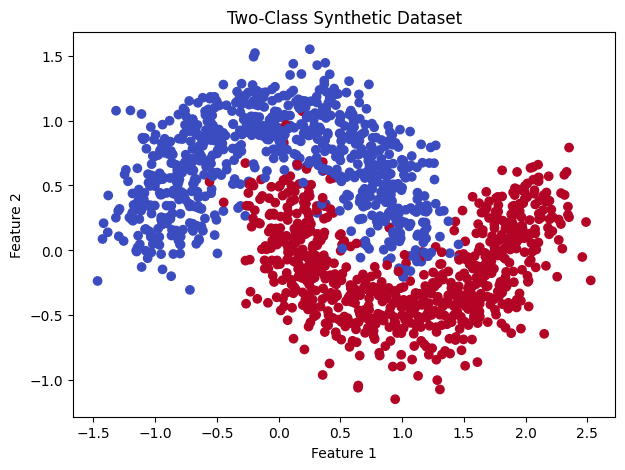

In [5]:
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm")
plt.title("Two-Class Synthetic Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [6]:
class LinearModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(2, 1)

    def forward(self, x):
        return self.fc(x)

print("Linear model created!")

Linear model created!


In [7]:
class NeuralNetwork(nn.Module):
    def __init__(self, hidden_size=16):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, 1)
        )

    def forward(self, x):
        return self.network(x)

print("Nonlinear neural network created!")

Nonlinear neural network created!


In [8]:
def train_model(model, learning_rate=0.01, epochs=100):
    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate
    )
    loss_function = nn.BCEWithLogitsLoss()

    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        model.train()

        optimizer.zero_grad()
        outputs = model(X_train)
        loss = loss_function(outputs, y_train)
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

        model.eval()
        with torch.no_grad():
            val_output = model(X_val)
            val_loss = loss_function(val_output, y_val)

        val_losses.append(val_loss.item())

    return model, train_losses, val_losses

print("Training function ready!")

Training function ready!


In [9]:
linear_model = LinearModel()

linear_model, linear_train_loss, linear_val_loss = train_model(
    linear_model, learning_rate=0.01, epochs=100
)

print("Linear model training completed!")

Linear model training completed!


In [10]:
hidden_sizes = [4, 8, 16, 32]
results = []
models = {}

for size in hidden_sizes:
    torch.manual_seed(42)

    model = NeuralNetwork(hidden_size=size)
    model, train_loss, val_loss = train_model(
        model, learning_rate=0.01, epochs=100
    )

    with torch.no_grad():
        val_predictions = (
            torch.sigmoid(model(X_val)) >= 0.5
        ).int().numpy().ravel()

    val_accuracy = accuracy_score(
        y_val.numpy().ravel(), val_predictions
    )

    models[size] = model

    results.append({
        "Hidden Neurons": size,
        "Validation Accuracy": val_accuracy
    })

hidden_results = pd.DataFrame(results)
print(hidden_results)

   Hidden Neurons  Validation Accuracy
0               4             0.884444
1               8             0.902222
2              16             0.902222
3              32             0.928889


In [11]:
learning_rates = [0.001, 0.01, 0.1]
lr_results = []
lr_models = {}

for lr in learning_rates:
    torch.manual_seed(42)

    model = NeuralNetwork(hidden_size=16)
    model, train_loss, val_loss = train_model(
        model, learning_rate=lr, epochs=100
    )

    with torch.no_grad():
        val_predictions = (
            torch.sigmoid(model(X_val)) >= 0.5
        ).int().numpy().ravel()

    val_accuracy = accuracy_score(
        y_val.numpy().ravel(), val_predictions
    )

    lr_models[lr] = model

    lr_results.append({
        "Learning Rate": lr,
        "Validation Accuracy": val_accuracy
    })

lr_results = pd.DataFrame(lr_results)
print(lr_results)

   Learning Rate  Validation Accuracy
0          0.001             0.835556
1          0.010             0.902222
2          0.100             0.964444


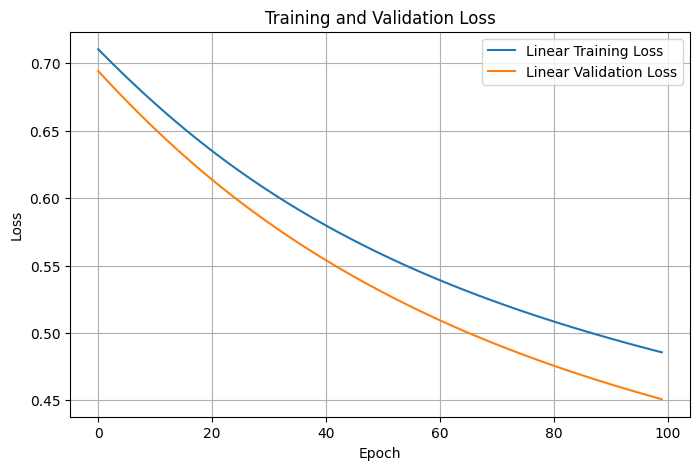

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(linear_train_loss, label="Linear Training Loss")
plt.plot(linear_val_loss, label="Linear Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
print("Hidden Layer Comparison:")
display(hidden_results)

print("Learning Rate Comparison:")
display(lr_results)

Hidden Layer Comparison:


,Hidden Neurons,Validation Accuracy
0,4,0.884444
1,8,0.902222
2,16,0.902222
3,32,0.928889


Learning Rate Comparison:


,Learning Rate,Validation Accuracy
0,0.001,0.835556
1,0.010,0.902222
2,0.100,0.964444


In [14]:
best_size = max(
    hidden_results.to_dict("records"),
    key=lambda row: row["Validation Accuracy"]
)["Hidden Neurons"]

best_model = models[best_size]

with torch.no_grad():
    test_predictions = (
        torch.sigmoid(best_model(X_test)) >= 0.5
    ).int().numpy().ravel()

test_accuracy = accuracy_score(y_test, test_predictions)

print("Best hidden-layer size:", best_size)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Best hidden-layer size: 32
Test Accuracy: 94.22 %


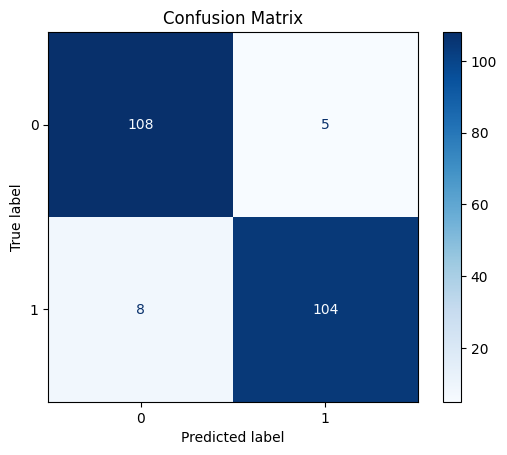

In [15]:
cm = confusion_matrix(y_test, test_predictions)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)

display_matrix.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [16]:
print("CONCLUSION")
print("1. A linear model creates a straight decision boundary.")
print("2. A nonlinear neural network can learn curved patterns.")
print("3. Hidden-layer size affects model performance.")
print("4. Learning rate affects the training process.")
print("5. Validation accuracy helps select a suitable model.")
print("6. Test accuracy evaluates performance on unseen data.")

CONCLUSION
1. A linear model creates a straight decision boundary.
2. A nonlinear neural network can learn curved patterns.
3. Hidden-layer size affects model performance.
4. Learning rate affects the training process.
5. Validation accuracy helps select a suitable model.
6. Test accuracy evaluates performance on unseen data.
